In [ ]:
from nupack import *
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# DNA Hybridization & Thermodynamics Analysis with NUPACK

## Overview
This notebook uses the **NUPACK** Python library to investigate DNA secondary structure, duplex/trimer thermodynamics, concentration-dependent hybridization equilibrium, and sequence specificity.

### Topics Covered
1. **Single-Strand vs. Duplex MFE:** Calculating Minimum Free Energy (MFE) structures and visualizing secondary structure folding.
2. **Complex Size & Ensemble Thermodynamics:** Comparing MFE and partition-function ensemble free energy ($\Delta G$) up to $n = 2$ (dimers) and $n = 3$ (trimers) using `tube_analysis`.
3. **Concentration Effects:** Evaluating how strand concentration ($10^{-6}\,\mathrm{M}$ vs. $10^{-9}\,\mathrm{M}$) shifts equilibrium yields in a three-strand system.
4. **Random Sequence Interaction Distribution:** Sampling 200 random 20-nt sequences against a fixed test strand to inspect the background hybridization MFE distribution.
5. **Genomic Specificity Calculation:** Estimating the expected number of random occurrences of a 20-nt probe in a $10^9\,\mathrm{bp}$ genome.

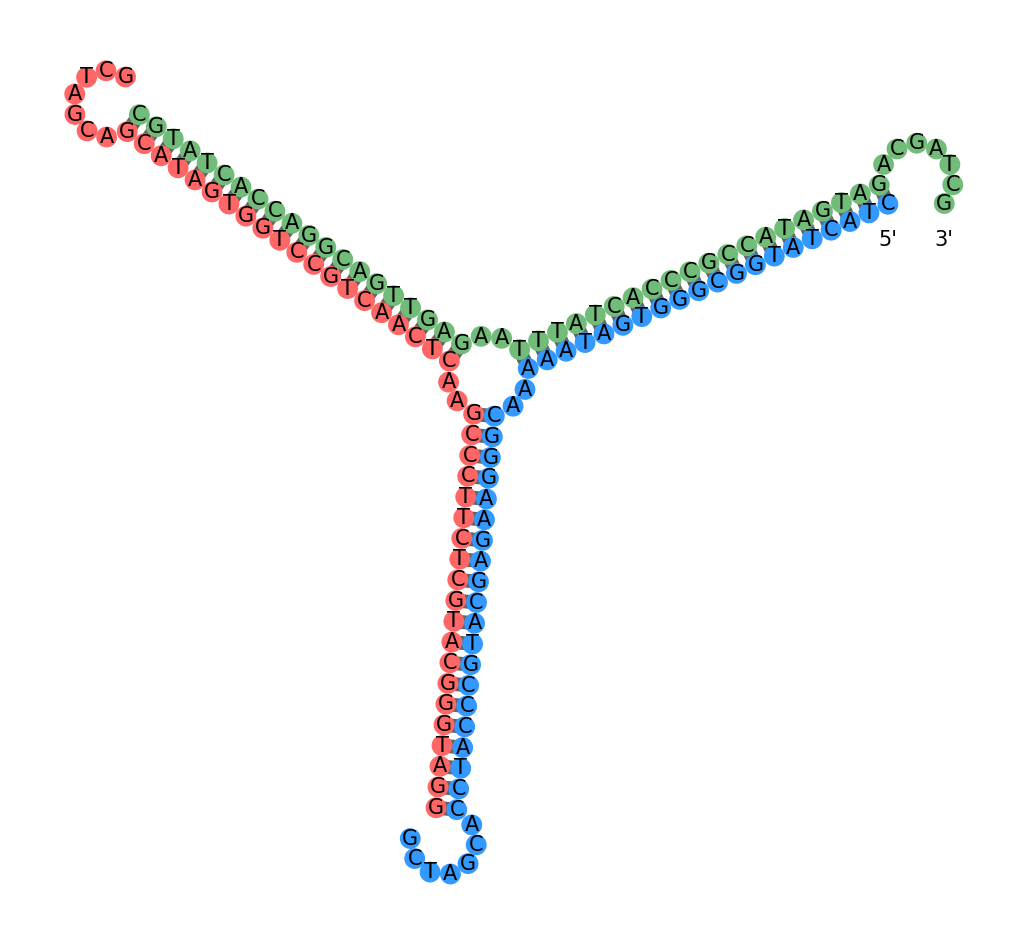

In [1]:
from draw_rna.draw import draw_rna

seqs=["CTACTATGGCGGGTGATAAAAACGGGAAGAGCATGCCCATCCACGATCG","GGATGGGCATGCTCTTCCCGAACTCAACTGCCTGGTGATACGACGATCG","CGTATCACCAGGCAGTTGAGAATTTATCACCCGCCATAGTAGACGATCG"]

T=20
sodium=1
model=Model(material="dna",celsius=T, sodium=sodium)


def drawseq(seqs,structure=None,T=20,sodium=1):
# NUPACK style: Use '+' to separate strands


    model=Model(material="dna",celsius=T, sodium=sodium)
    a=mfe(seqs,model)
    sequence=""
    colors=""
    colori="brgym"
    for seq,c in zip(seqs,colori):
        sequence=sequence+" "+seq
        colors=colors+c*len(seq)+"w"
    sequence=sequence[1:]
    if not structure:
        structure=str(a[0].structure)

# Create a color list (one color for each nucleotide)
# For a simple plot, we can just make them all 'black' or 'blue'

    fig,ax=plt.subplots(figsize=(13,13))
# Pass the colors list to satisfy the function requirements
    draw_rna(sequence*2, structure, color_list=colors*2, ax=ax)

drawseq(seqs)
plt.axis('off')
plt.show()

Sequence: ['GCAACGCGACTGCGTTCGCT']
MFE Energy: -8.020143508911133 kcal/mol
MFE Structure: (((((((....))))).)).


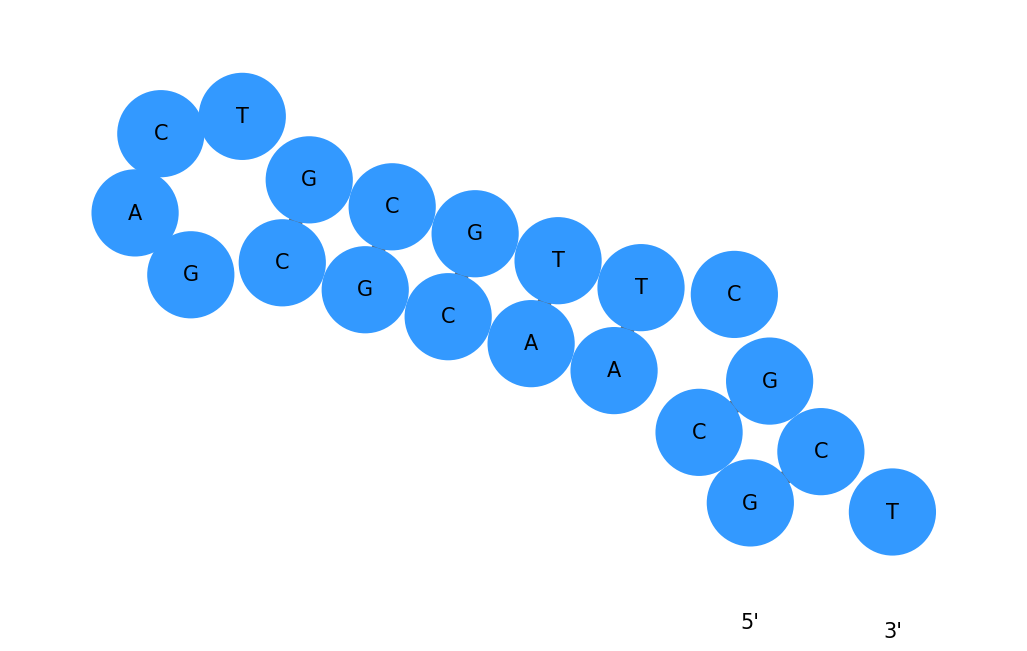

In [2]:
#Question 1: part A
my_model = Model(material='dna', celsius=20, sodium=1.0)

# I chose a sequence with high GC
my_sequence = ["GCAACGCGACTGCGTTCGCT"]

mfe_result = mfe(strands=my_sequence, model=my_model)
energy = mfe_result[0].energy
structure = mfe_result[0].structure

print(f"Sequence: {my_sequence}")
print(f"MFE Energy: {energy} kcal/mol")
print(f"MFE Structure: {structure}")

drawseq(my_sequence) 
plt.show()

For the single strand analysis, the MFE represents the energy required for the DNA sequence to fold onto itself. The negative energy value indicates the stability of the formed secondary structures, such as small hairpins.

Complex Energy: -39.98 kcal/mol
Complex Structure: ((((((((((((((((((((+))))))))))))))))))))


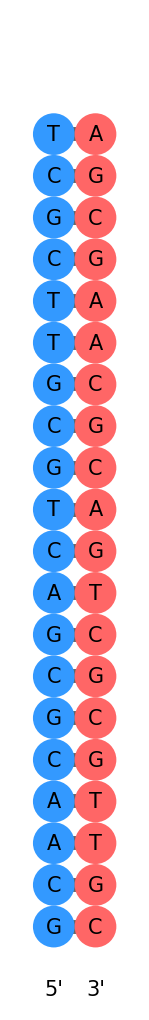

In [3]:
#Question 1: part B
My_seqs=["GCAACGCGACTGCGTTCGCT","AGCGAACGCAGTCGCGTTGC"]
res_complex = mfe(strands=My_seqs, model=my_model)


print(f"Complex Energy: {res_complex[0].energy:.2f} kcal/mol")
print(f"Complex Structure: {res_complex[0].structure}")

drawseq(My_seqs)
plt.show()

By comparing the results of Exercises 1 and 2, we observe that the binding of two complementary strands results in a much lower (more negative) Free Energy. For a single strand, the energy was around -8.02 kcal/mol, whereas for the complex, it decreased. This happens because the hybridization process forms a full double-helix structure with maximum hydrogen bonding and base-stacking, which is much more stable than a single strand folding into a hairpin.

In [4]:
# Define two sequences (the last one and its complement)

seq1 = Strand("GCAACGCGACTGCGTTCGCT", name='strand1')
seq2 = Strand("AGCGAACGCAGTCGCGTTGC", name='strand2')

# Creating the Tube (1 micromolar each)
# We check for monomers (n=1) and dimers (n=2)
my_tube = Tube(strands={seq1: 1e-6, seq2: 1e-6}, complexes=SetSpec(max_size=2), name='Dimer_Tube')

tube_results = tube_analysis(tubes=[my_tube], model=model, compute=['pfunc', 'mfe'])
tube_results

Result(tubes={<Tube Dimer_Tube>: <nupack.analysis.TubeResult object at 0x7301fdacaa80>}, complexes=<nupack.analysis.ComplexDict object at 0x7301fd451790>)

In [5]:
# Change max_size to 3 to include trimers (complexes of 3 strands)

my_tube = Tube(strands={seq1: 1e-6, seq2: 1e-6}, 
               complexes=SetSpec(max_size=3), 
               name='Trimer_Tube')

tube_results = tube_analysis(tubes=[my_tube], model=model, compute=['pfunc', 'mfe'])
tube_results

Result(tubes={<Tube Trimer_Tube>: <nupack.analysis.TubeResult object at 0x7301fd581e20>}, complexes=<nupack.analysis.ComplexDict object at 0x7301fd499220>)

As we increase the maximum complex size to n=3, we observe that the magnitude of Free Energy continues to grow. For example, the trimer (strand1+strand2+strand2) has a Delta G of -51.25 kcal/mol, which is much lower than the dimer at -40.33 kcal/mol. This growth occurs because the system accounts for more total interactions and bonds as more strands are added.

Despite the trimers having more negative Delta G, their equilibrium concentrations are extremely low. The heterodimer (strand1+strand2) remains the dominant species at 1.000e-06. This indicates that while larger complexes are theoretically possible and energetically favorable, the system is stoichiometrically saturated as a duplex.

In all cases, the MFE energy is higher (less negative) than the Free Energy (Delta G). This is because the MFE only considers the single most stable structure, while Delta G accounts for the entire thermodynamic ensemble (Partition Function). The inclusion of all possible microstates in the calculation always results in a more stable (lower) total Free Energy for the system.

In [6]:
seq1 = Strand("GCAACGCGACTGCGTTCGCT", name='strand1')
seq2 = Strand("AGCGAACGCAGTCGCGTTGC", name='strand2') 
seq3 = Strand("TGGACACTGGTACGAGCTGA", name='strand3') 

print("Result for High Concentration")
tube_high = Tube(strands={seq1: 1e-6, seq2: 1e-6, seq3: 1e-6}, complexes=SetSpec(max_size=2), name='tube_high')
results_high = tube_analysis(tubes=[tube_high], model=model)
print(results_high)

print("Result for Low Concentration")
tube_low = Tube(strands={seq1: 1e-9, seq2: 1e-9, seq3: 1e-9}, complexes=SetSpec(max_size=2), name='low_tube')
results_low = tube_analysis(tubes=[tube_low], model=model)
print(results_low)

Result for High Concentration
Complex results:
             Complex       Pfunc dG (kcal/mol)
0          (strand1)   1.2161e+6        -8.162
1          (strand2)   9.2217e+5        -8.001
2          (strand3)   3.2827e+1        -2.034
3  (strand1+strand1)  3.6767e+16       -22.220
4  (strand1+strand2)  1.1610e+30       -40.327
5  (strand1+strand3)  2.6853e+12       -16.672
6  (strand2+strand2)  1.5824e+16       -21.729
7  (strand2+strand3)  7.9229e+11       -15.961
8  (strand3+strand3)   1.2305e+9       -12.193
Concentration results:
          Complex tube_high (M)  
(strand1+strand2)     1.000e-06  
        (strand3)     9.619e-07  
(strand3+strand3)     1.907e-08  
        (strand1)     7.319e-12  
        (strand2)     7.313e-12  
(strand1+strand3)     8.546e-15  
(strand2+strand3)     3.323e-15  
(strand1+strand1)     2.403e-20  
(strand2+strand2)     1.796e-20  
Result for Low Concentration
Complex results:
             Complex       Pfunc dG (kcal/mol)
0          (strand1)   1.21

When the concentration is High (10^{-6} M), the formation of the duplex (strand1+strand2) is nearly 100%, meaning the hybridization is complete. However, at Low Concentration (10^{-9} M), the equilibrium starts to shift, and the relative stability of the complex decreases compared to the single-stranded state.
This follows the Law of Mass Action. In DNA nanotechnology, higher concentrations increase the probability of complementary strands encountering each other. At lower concentrations, the system's entropy favors the dissociated state, making it harder for complexes to form even if their binding energy is favorable.

In [ ]:
import random

# Fixed 20-nt test sequence
test_strand = Strand("GCAACGCGACTGCGTTCGCT", name='test_strand')

n_sequences = 200
sequence_length = 20
energies = []
bases = ['A', 'C', 'G', 'T']

random.seed(42)
for i in range(n_sequences):
    rand_seq = "".join(random.choice(bases) for _ in range(sequence_length))
    tmp_strand = Strand(rand_seq, name=f'rand_{i}')
    
    # Compute MFE of interaction between the test strand and the random strand
    res = mfe(strands=[test_strand, tmp_strand], model=model)
    energies.append(res[0].energy)

plt.figure(figsize=(10, 6))
plt.hist(energies, bins=15, color='lightblue', edgecolor='black')
plt.title(f'Distribution of Interaction MFE for {n_sequences} Random DNA Sequences vs. Test Strand', fontsize=12)
plt.xlabel('Minimum Free Energy (kcal/mol)', fontsize=12)
plt.ylabel('Number of Sequences (Frequency)', fontsize=12)
plt.grid(alpha=0.3)
plt.show()

The histogram shows a right-skewed distribution of Minimum Free Energies (MFE) for the random DNA sequences.
Peak at 0 kcal/mol: A large majority of the random sequences have an MFE close or exactly 0.0 kcal/mol. This indicates that most random 20nt sequences do not form stable secondary structures under the given conditions.
This distribution proves that thermodynamic stability is not a common feature of random sequences. Highly stable structures (Exercise 1 and 2) are statistically rare and require specific base-pairing arrangements. The test sequence we chose earlier is much more stable than the average random sequence in this distribution.

In [7]:
N = 20
L = 1e9
# Probability of an exact match with 4 bases (A, C, G, T)
probability = (1 / 4) ** N

# Expected number of occurrences in a genome of length L
expected_hits = L * probability

print(f"Sequence Length (N): {N}")
print(f"Genome Length (L): {L:.0e} bp")
print(f"Probability of occurrence: {probability:.2e}")
print(f"Expected number of hits: {expected_hits:.6f}")

if expected_hits < 0.1:
    print("Conclusion: N=20 is a good choice for sequence specificity.")
else:
    print("Conclusion: N is too short.")

Sequence Length (N): 20
Genome Length (L): 1e+09 bp
Probability of occurrence: 9.09e-13
Expected number of hits: 0.000909
Conclusion: N=20 is a GOOD.


To evaluate if N=20 is an appropriate length for biological applications, I calculate the expected number of random occurrences in a large genome (L = 10^9 bp). The probability of a specific 20-nt sequence occurring by chance is very low (9.09 × 10^{-13}). In a genome of 1 billion base pairs, we expect to find this sequence only 0.0009 times.
Since the expected number of hits is significantly below 1, N=20 is a good choice. It provides enough complexity to ensure that the sequence will bind only to its specific target and not to random locations in the genome.